In [1]:
# Configuración de entornos y backends (DEBE ir antes de importar Keras)
import os
os.environ["KERAS_BACKEND"] = "torch"

# Instalación silenciosa de dependencias obligatorias
%pip install -q datasets pillow tensorflow

# Framework de Deep Learning
import keras
from keras import layers
import torch

# Librerías del sistema y utilidades estándar
import json
from io import BytesIO
from pathlib import Path
from urllib.request import urlopen

# Computación científica y matemática
import numpy as np
import scipy.stats as stats

# Visualización de datos, gráficos y animaciones
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display

# Procesamiento de imágenes
from PIL import Image, ImageOps

# Carga de conjuntos de datos y modelos distribuidos
from datasets import load_dataset

/usr/local/lib/python3.13/dist-packages/jax/_src/cloud_tpu_init.py:86: UserWarning: Transparent hugepages are not enabled. TPU runtime startup and shutdown time should be significantly improved on TPU v5e and newer. If not already set, you may need to enable transparent hugepages in your VM image (sudo sh -c "echo always > /sys/kernel/mm/transparent_hugepage/enabled")
  warnings.warn(


std(e): 0.5835577367629308


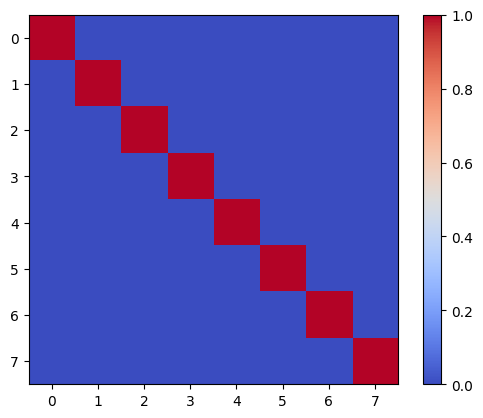

In [2]:
my_cmap = "coolwarm"

N = 8
Zr = stats.norm(loc=0, scale=1)
Z = Zr.rvs(size=N*N)
sigma=0.5
epsilon = sigma*Z
e = epsilon
print("std(e):",np.std(epsilon))

X = np.eye(N)
x = X.flatten()  # Vector con N**2 píxeles

plt.imshow(x.reshape(N, N), cmap=my_cmap, vmin=0, vmax=1)
plt.colorbar()
plt.show()

ENTRADA: imágenes originales y niveles de ruido σ

Normalizar las imágenes
Separar datos de entrenamiento y evaluación
Inicializar los parámetros θ del modelo

REPETIR hasta completar el entrenamiento:
    Seleccionar un lote de imágenes originales x
    Seleccionar un nivel de ruido σ

    Generar ruido nuevo: e = σ · Normal(0, I)
    Construir imágenes perturbadas: y = x + e

    Calcular el campo objetivo: S_objetivo = −e / σ²
    Predecir el campo: S_predicho = sθ(y, σ)

    Pérdida = ½ · promedio(||S_predicho − S_objetivo||²)
    Actualizar θ usando el gradiente de la pérdida

Evaluar el modelo con los datos reservados
SALIDA: campo aprendido sθ(y, σ)

Entrenamiento completado. Parámetro A final: -3.5714


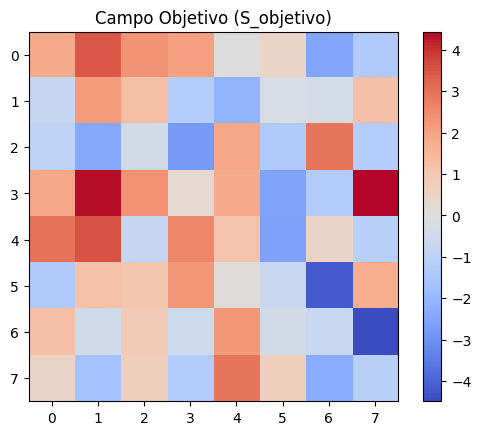

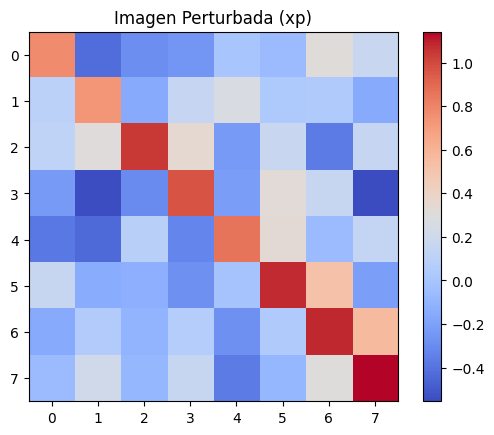

In [3]:
# Parámetros del problema y entrenamiento
N = 8
sigma = 0.5
lr_A = 0.01
lr_B = 0.01
n_pasos = 1000

# Inicializar los parámetros theta del modelo (A y B)
A = -0.1
B = np.zeros(N**2, dtype=np.float16)

# Imagen original (x)
X_original = np.eye(N)
x = X_original.flatten()  # Vector de 64 dimensiones

# Historial para graficar la pérdida inicializado directamente como un arreglo NumPy de baja precisión
historial_perdida = np.zeros(n_pasos, dtype=np.float16)

# Bucle de entrenamiento para aprender el campo s_theta(y) = A * y + B
for paso in range(n_pasos):
  # Generar ruido nuevo: e = sigma * Normal(0, I)
  e = np.random.normal(0, sigma, size=x.shape)
  # Construir imagen perturbada: y = x + e
  y = x + e
  # Calcular el campo objetivo: S_objetivo = -e / sigma^2
  S_objetivo = -e/(sigma**2)
  # Predecir el campo con el modelo lineal s_theta(y, sigma)
  S_predicho = A*y + B
  # Calcular la pérdida: 1/2 * promedio(||S_predicho - S_objetivo||^2)
  error = S_predicho - S_objetivo
  perdida = np.mean(error**2)/2
  historial_perdida[paso] = perdida
  # Gradientes con respecto a A y B
  grad_A = np.mean(error*y)
  grad_B = error
  # Actualizar parámetros usando el gradiente
  A -= lr_A*grad_A
  B -= lr_B*grad_B

print(f"Entrenamiento completado. Parámetro A final: {A:.4f}")

# Ruido gaussian
Sobjetivo = -e/sigma**2
plt.imshow(Sobjetivo.reshape(N, N), cmap=my_cmap)
plt.colorbar()
plt.title("Campo Objetivo (S_objetivo)")
plt.show()
plt.close()

xp = x + e*sigma
plt.imshow(xp.reshape(8,8), cmap=my_cmap)
plt.colorbar()
plt.title("Imagen Perturbada (xp)")
plt.show()
plt.close()

ENTRADA: imagen perturbada y, nivel de ruido σ,
         campo aprendido sθ

Calcular el campo: S = sθ(y, σ)

Estimar la imagen limpia:
    x_estimada = y + σ² · S

Si conocemos la imagen original:
    Comparar la estimación con ella
    Calcular el error de recuperación

SALIDA: imagen limpia estimada

Algoritmo de inferencia y score definido correctamente con los parámetros aprendidos.


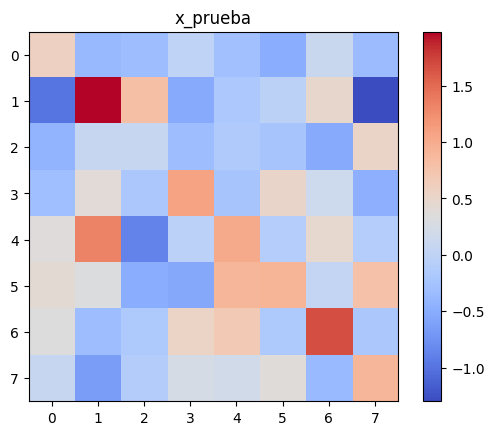

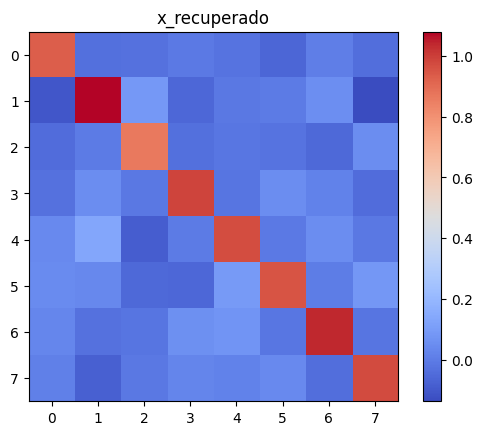

In [4]:
# Algoritmo de Estimación y Generación Completo
# Usamos los parámetros A y B ya aprendidos en el modelo anterior.

# 1. Definir función para predecir el score s_theta(y, sigma)
def score_predicho(y, A, B):
    return A * y + B

# 2. Reconstrucción directa
def estimar_limpia(y, sigma, S_predicho):
    return y + (sigma**2) * S_predicho

print("\033[1mAlgoritmo de inferencia y score definido correctamente con los parámetros aprendidos.\033[0m")
rng_prueba = np.random.default_rng(137)

e_prueba = rng_prueba.normal(0, sigma, size=x.shape)
x_prueba = x + e_prueba

# 2. Evaluar el campo aprendido.
S_prueba = A * x_prueba + B

# 3. Recuperar la imagen usando ese campo.
x_recuperado = x_prueba + sigma**2 * S_prueba

plt.imshow(x_prueba.reshape(8,8), cmap=my_cmap)
plt.colorbar()
plt.title("x_prueba")
plt.show()
plt.close()


plt.imshow(x_recuperado.reshape(8,8), cmap=my_cmap)
plt.colorbar()
plt.title("x_recuperado")
plt.show()
plt.close()

# Langevine

ENTRADA: campo aprendido, niveles σ de mayor a menor,
         número de pasos K y constante pequeña c

Inicializar desde ruido:
    Y = μ + σ_max · Normal(0, I)
    μ es la media de las imágenes de entrenamiento

PARA cada nivel σ, desde σ_max hasta σ_min:
    Elegir el paso: h = c · σ²

    REPETIR K veces:
        Calcular el campo: S = sθ(Y, σ)
        Generar ruido nuevo: Z = Normal(0, I)

        Actualizar mediante Langevin:
            Y = Y + h · S + √(2h) · Z

Opcionalmente aplicar la recuperación final:
    Y = Y + σ_min² · sθ(Y, σ_min)

SALIDA: imagen generada

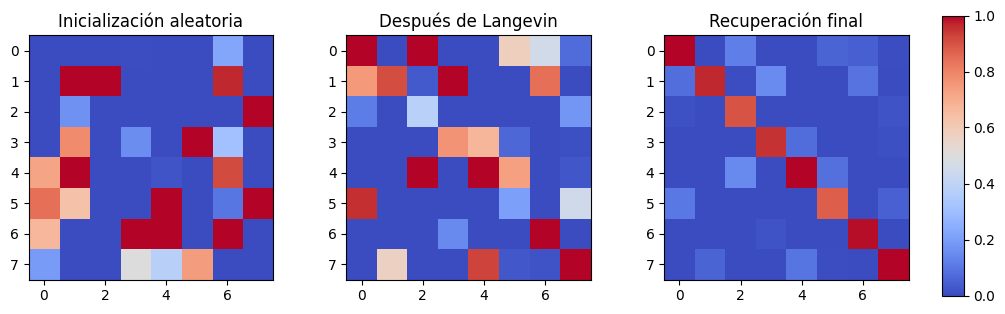

In [5]:
rng_generacion = np.random.default_rng(137)

# Inicialización independiente de la imagen original.
Y = rng_generacion.normal(0, 1, size=x.shape)
Y_inicial = Y.copy()

dt = 0.001  # Para sigma = 0.1 y A cercano a -100.
n_pasos = 1000

# Aquí entra Langevin.
for paso in range(n_pasos):
    S = A * Y + B
    Z = rng_generacion.normal(size=Y.shape)
    Y = Y + dt * S + np.sqrt(2 * dt) * Z

# Recuperación final: es una operación distinta.
Y_recuperada = Y + sigma**2 * (A * Y + B)

fig, ejes = plt.subplots(1, 3, figsize=(11, 4))

comparaciones = [
    (Y_inicial, "Inicialización aleatoria"),
    (Y, "Después de Langevin"),
    (Y_recuperada, "Recuperación final")
]

for eje, (imagen, titulo) in zip(ejes, comparaciones):
    im = eje.imshow(
        np.clip(imagen.reshape(N, N), 0, 1),
        cmap=my_cmap
    )
    eje.set_title(titulo)
    eje.axis("on")

# Barra de colores global compartida
plt.subplots_adjust(left=0.05, right=0.85, wspace=0.3)
cbar_ax = fig.add_axes([0.88, 0.15, 0.02, 0.7])
fig.colorbar(im, cax=cbar_ax)

plt.show()

# Caso con más imagenes

In [6]:
# Cargando el conjunto de datos de CIFAR-10 de forma eficiente en streaming
datos = load_dataset(
    "uoft-cs/cifar10",
    split="train",
    streaming=True
)
perros = list()

for ejemplo in datos:
    if ejemplo["label" ] == 5:  # Categoría de perro en CIFAR-10
        perros.append(np.array(ejemplo["img"].convert("RGB")))
        if len(perros) % 25 == 0:
            print(f"\rCargados: {len(perros)} perros", end="", flush=True)
        if len(perros) == 1000:
            break

Cargados: 1000 perros

Forma: (1000, 32, 32, 3)


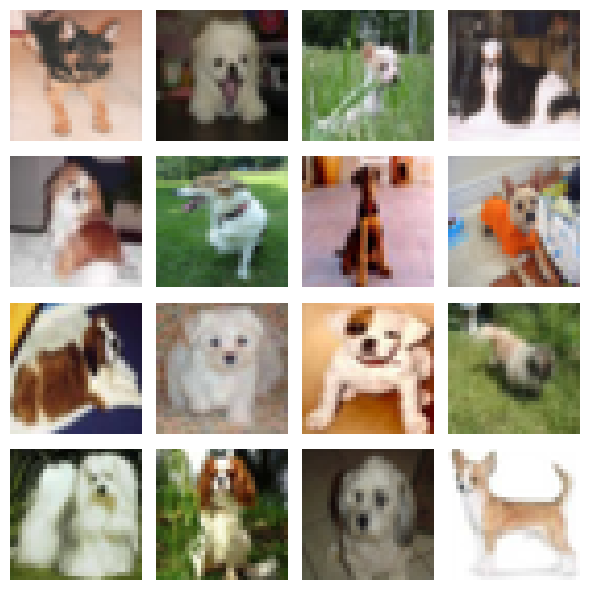

In [7]:
X_perros = np.stack(perros)
print("Forma:", X_perros.shape)

fig, axes = plt.subplots(4, 4, figsize=(6, 6))
for ax, imagen in zip(axes.ravel(), X_perros[:16]):
    ax.imshow(imagen)
    ax.axis("off")

plt.tight_layout()
plt.show()

Forma: (1000, 32, 32, 3)


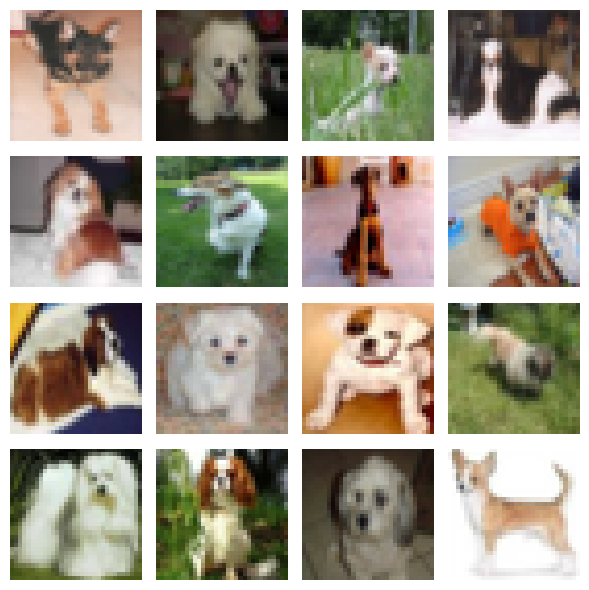

In [8]:
X_entrenamiento = X_perros.astype(np.float32)/127.5 - 1.0
print("Forma:", X_entrenamiento.shape)
fig, axes = plt.subplots(4, 4, figsize=(6, 6))
for ax, imagen in zip(axes.ravel(), X_entrenamiento[:16]):
    # Reescalar temporalmente de [-1, 1] a [0, 1] para evitar el warning de clipping de matplotlib
    ax.imshow(np.clip((imagen + 1) / 2, 0.0, 1.0))
    ax.axis("off")

plt.tight_layout()
plt.show()

In [9]:
rng = np.random.default_rng(137)
sigma = 0.3

# Ruido independiente para cada imagen, píxel y canal
epsilon = rng.normal(
    loc=0,
    scale=sigma,
    size=X_entrenamiento.shape
).astype(np.float32)

X_ruidosas = X_entrenamiento + epsilon

# Campo objetivo para entrenar
S_objetivo = -epsilon / sigma**2

print("Imágenes limpias:", X_entrenamiento.shape)
print("Imágenes ruidosas:", X_ruidosas.shape)
print("Score objetivo:", S_objetivo.shape)

Imágenes limpias: (1000, 32, 32, 3)
Imágenes ruidosas: (1000, 32, 32, 3)
Score objetivo: (1000, 32, 32, 3)


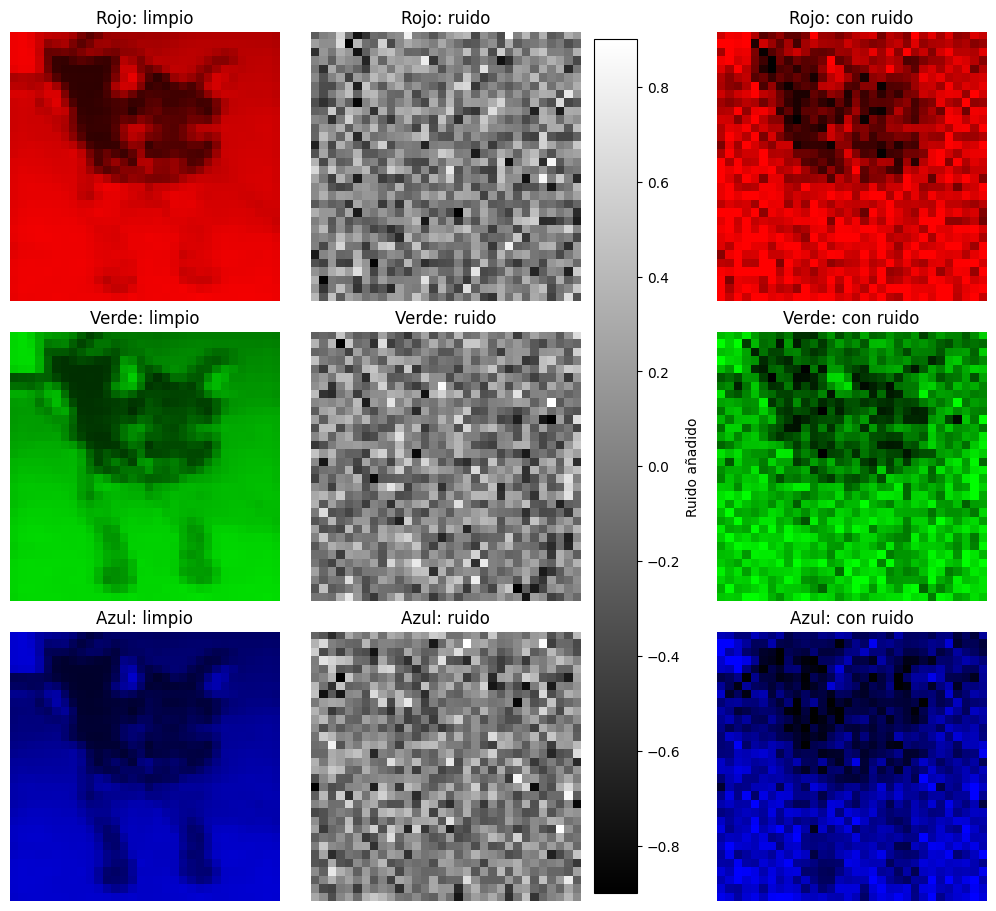

In [10]:
i = 0
limpia = np.clip((X_entrenamiento[i] + 1) / 2, 0, 1)
ruidosa = np.clip((X_ruidosas[i] + 1) / 2, 0, 1)

nombres = ["Rojo", "Verde", "Azul"]

fig, axes = plt.subplots(
    3, 3, figsize=(10, 9), constrained_layout=True
)

for canal, nombre in enumerate(nombres):

    # Mostrar únicamente este canal en su color
    limpia_canal = np.zeros_like(limpia)
    limpia_canal[:, :, canal] = limpia[:, :, canal]

    ruidosa_canal = np.zeros_like(ruidosa)
    ruidosa_canal[:, :, canal] = ruidosa[:, :, canal]

    axes[canal, 0].imshow(limpia_canal)
    axes[canal, 0].set_title(f"{nombre}: limpio")

    im = axes[canal, 1].imshow(
        epsilon[i, :, :, canal],
        cmap="gray",
        vmin=-3 * sigma,
        vmax=3 * sigma
    )
    axes[canal, 1].set_title(f"{nombre}: ruido")

    axes[canal, 2].imshow(ruidosa_canal)
    axes[canal, 2].set_title(f"{nombre}: con ruido")

for ax in axes.ravel():
    ax.axis("off")

fig.colorbar(
    im,
    ax=axes[:, 1].tolist(),
    shrink=1,
    label="Ruido añadido"
)

plt.show()

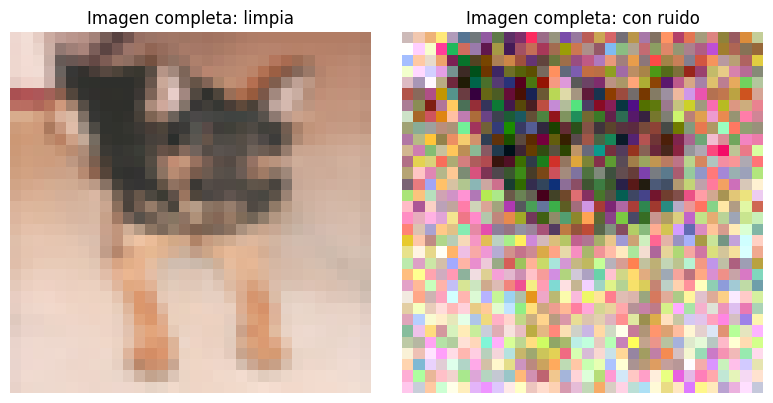

In [11]:
i = 0
fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(
    np.clip((X_entrenamiento[i] + 1) / 2, 0, 1)
)
axes[0].set_title("Imagen completa: limpia")
axes[1].imshow(
    np.clip((X_ruidosas[i] + 1) / 2, 0, 1)
)
axes[1].set_title("Imagen completa: con ruido")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

In [12]:
# Definir generador de números aleatorios para barajar reproduciblemente
rng_split = np.random.default_rng(137)
indices = rng_split.permutation(len(X_entrenamiento))

# Proporción de separación (80% entrenamiento, 20% evaluación)
corte = int(0.8 * len(X_entrenamiento))
indices_entrenamiento = indices[:corte]
indices_evaluacion = indices[corte:]

datos = X_entrenamiento[indices_entrenamiento]
evaluacion = X_entrenamiento[indices_evaluacion]

# Parámetros iniciales del modelo lineal
a = 0.0
B = np.zeros_like(datos[0])

D = B.size  # Número de componentes: píxeles × canales

lr_a = 0.01
lr_B = lr_a * D  # Compensa el promedio sobre D componentes

print("datos len:", len(datos))
print("evaluacion len:", len(evaluacion))

datos len: 800
evaluacion len: 200


Paso 2000/2000 | pérdida: 3.7291
a aprendido: -3.0285645


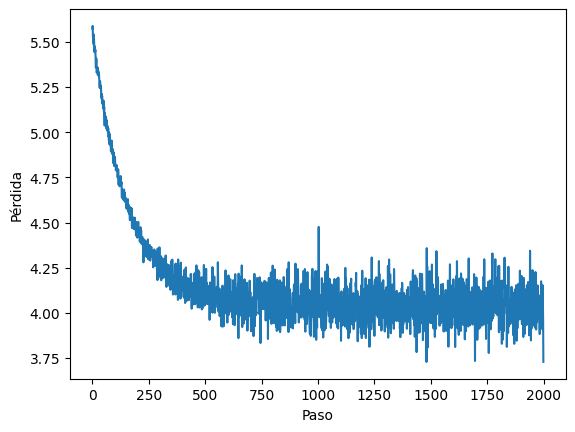

In [13]:
n_pasos = 2000
historia = []
for paso in range(n_pasos):
    # Seleccionar un grupo de imágenes
    indices = rng.integers(0, len(datos), size=32)
    X = datos[indices]
    # Agregar ruido nuevo
    epsilon = rng.normal(0, sigma, size=X.shape).astype(np.float32)
    Y = X + epsilon
    # Score objetivo y score predicho
    S_objetivo = -epsilon / sigma**2

    S_predicho = a * Y + B

    error = S_predicho - S_objetivo
    loss = 0.5 * np.mean(error**2)
    # Gradientes de esa pérdida
    grad_a = np.mean(error * Y)
    grad_B = np.mean(error, axis=0) / D

    # Actualizar los parámetros
    a -= lr_a * grad_a
    B -= lr_B * grad_B

    historia.append(loss)

    if (paso + 1) % 50 == 0:
        print(f"\rPaso {paso + 1}/{n_pasos} | pérdida: {loss:.4f}", end="", flush=True)

print("\na aprendido:", a)

plt.plot(historia)
plt.xlabel("Paso")
plt.ylabel("Pérdida")
plt.show()

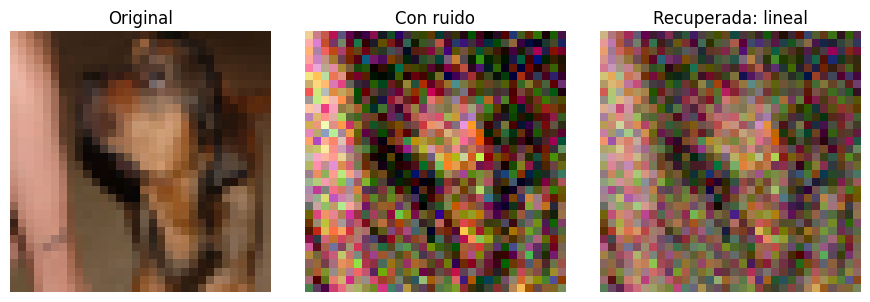

MSE con ruido: 0.08947834
MSE recuperada: 0.064195275


In [14]:
X = evaluacion[4]

epsilon = rng.normal(
    0, sigma, size=X.shape
).astype(np.float32)

Y = X + epsilon

S_predicho = a * Y + B
X_recuperada = Y + sigma**2 * S_predicho

fig, axes = plt.subplots(1, 3, figsize=(9, 3))

imagenes = [X, Y, X_recuperada]
titulos = ["Original", "Con ruido", "Recuperada: lineal"]

for ax, imagen, titulo in zip(axes, imagenes, titulos):
    ax.imshow(np.clip((imagen + 1) / 2, 0, 1))
    ax.set_title(titulo)
    ax.axis("off")

plt.tight_layout()
plt.show()

print("MSE con ruido:", np.mean((Y - X)**2))
print("MSE recuperada:", np.mean((X_recuperada - X)**2))

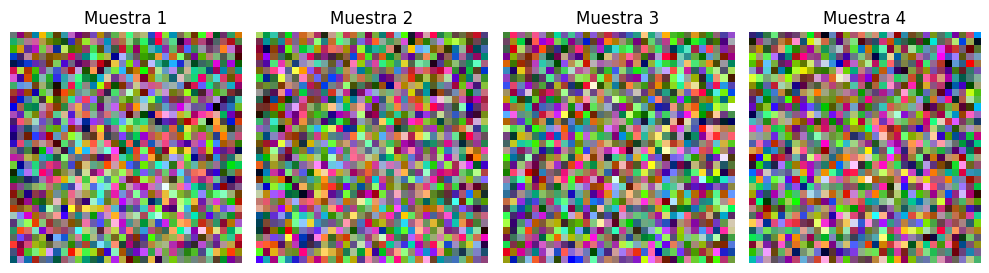

In [15]:
rng = np.random.default_rng(123)

if a >= 0:
    raise ValueError("Necesitamos a < 0 para tener una distribución estable.")

# Cuatro imágenes inicializadas con ruido puro
Y = rng.normal(size=(4,) + B.shape).astype(np.float32)

dt = 0.05 / abs(a)  # Paso pequeño respecto a la escala del campo

for paso in range(1000):
    S = a * Y + B
    Z = rng.normal(size=Y.shape)
    Y = Y + dt * S + np.sqrt(2 * dt) * Z

fig, axes = plt.subplots(1, 4, figsize=(10, 3))
for i, ax in enumerate(axes):
    ax.imshow(np.clip((Y[i] + 1) / 2, 0, 1))
    ax.set_title(f"Muestra {i + 1}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [16]:
rng = np.random.default_rng(137)

if a >= 0:
    raise ValueError("Necesitamos a < 0.")

n_muestras = 200

Y = rng.normal(
    size=(n_muestras,) + B.shape
).astype(np.float32)

dt = 0.05 / abs(a)

for paso in range(1000):
    S = a * Y + B
    Z = rng.normal(size=Y.shape).astype(np.float32)

    Y = Y + dt * S + np.sqrt(2 * dt) * Z
# Promedio de las muestras, sin recortar sus valores
promedio = Y.mean(axis=0)
# Promedio esperado del modelo lineal
media_modelo = -B / a

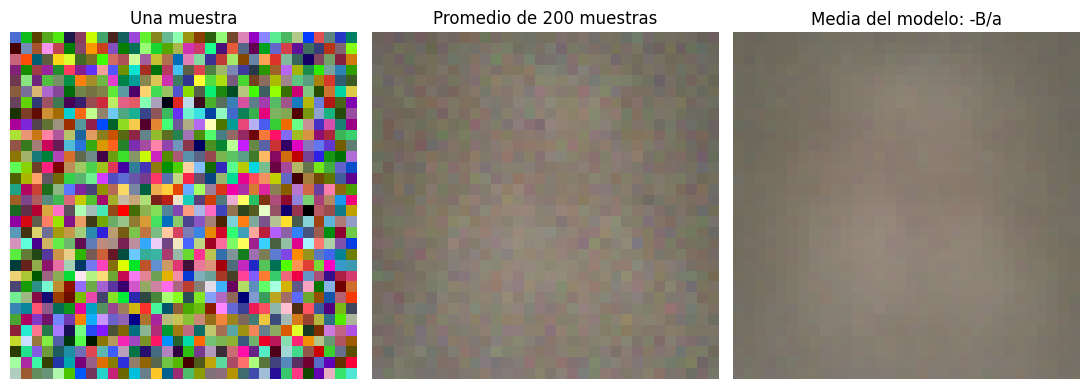

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(11, 4))

imagenes = [Y[0], promedio, media_modelo]
titulos = [
    "Una muestra",
    f"Promedio de {n_muestras} muestras",
    "Media del modelo: -B/a"
]

for ax, imagen, titulo in zip(axes, imagenes, titulos):
    ax.imshow(np.clip((imagen + 1) / 2, 0, 1))
    ax.set_title(titulo)
    ax.axis("off")

plt.tight_layout()
plt.show()

Forma: (50, 64, 64, 3)


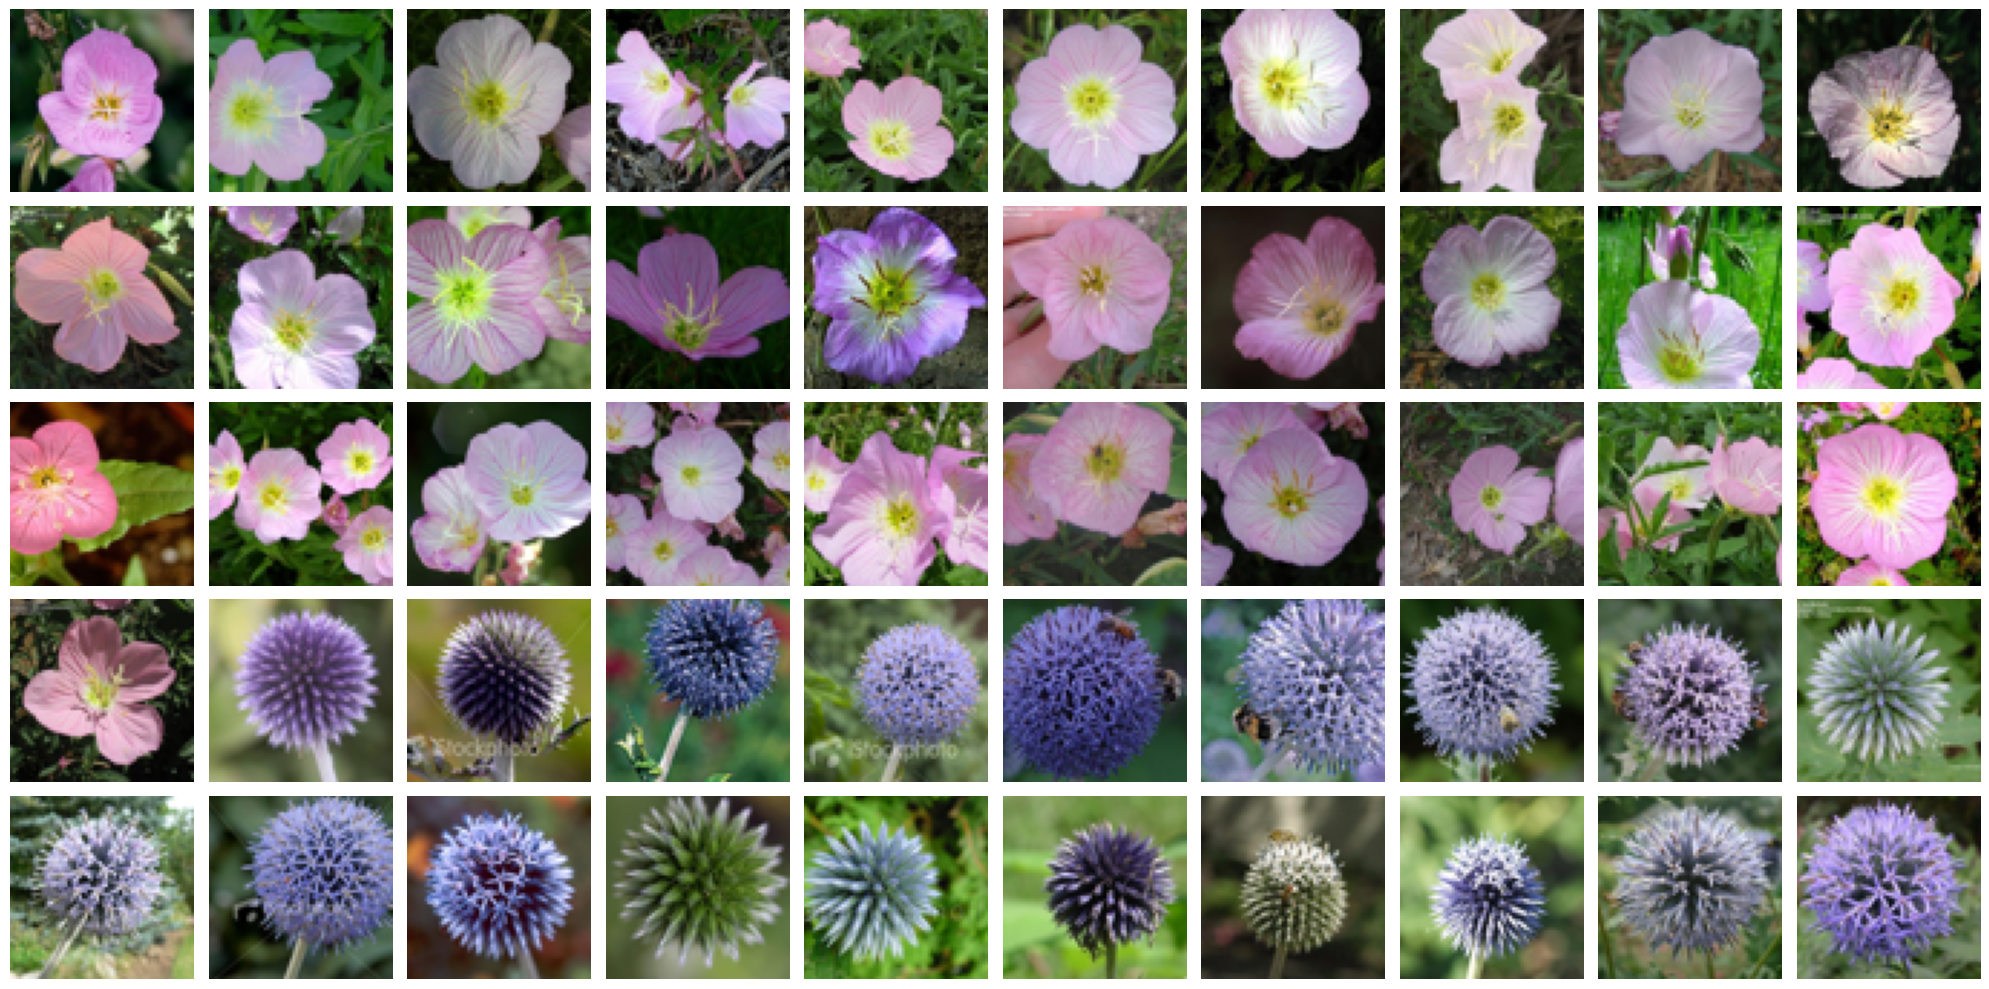

In [18]:
N = 50
my_size = 64
imagenes = list()

carpeta = Path("flores_64")
carpeta.mkdir(exist_ok=True)

url = (
    "https://datasets-server.huggingface.co/rows?"
    "dataset=nkirschi/oxford-flowers&config=default&split=train"
    f"&offset=0&length={N}"
)

# Consultar únicamente las imágenes solicitadas.
with urlopen(url, timeout=60) as respuesta:
    filas = json.load(respuesta)["rows"]

for i, fila in enumerate(filas):
    archivo = carpeta / f"flor_{i:03d}.png"

    if not archivo.exists():
        with urlopen(fila["row"]["image"]["src"], timeout=60) as respuesta:
            imagen = Image.open(BytesIO(respuesta.read())).convert("RGB")

        imagen = ImageOps.fit(imagen, (my_size, my_size))
        imagen.save(archivo)

    with Image.open(archivo) as imagen:
        imagenes.append(np.array(imagen))

# Valores entre 0 y 1, listos para trabajar después con Keras.
imagenes = np.array(imagenes, dtype="float32") / 255.0

# Visualizar las flores de manera automática y dinámica
print("Forma:", imagenes.shape)

n_imagenes = len(imagenes)
# Calcular columnas (hasta un máximo de 10) y filas dinámicamente
columnas = min(10, n_imagenes)
filas_grid = int(np.ceil(n_imagenes / columnas))

fig, ejes = plt.subplots(filas_grid, columnas, figsize=(2 * columnas, 2 * filas_grid))

# Asegurar que ejes sea iterable como array plano aun si es 1D o un solo subplot
for i, eje in enumerate(np.array(ejes).flat):
    if i < n_imagenes:
        eje.imshow(imagenes[i])
    eje.axis("off")

plt.tight_layout()
plt.show()

Entrenamiento: (40, 64, 64, 3)
Test: (10, 64, 64, 3)


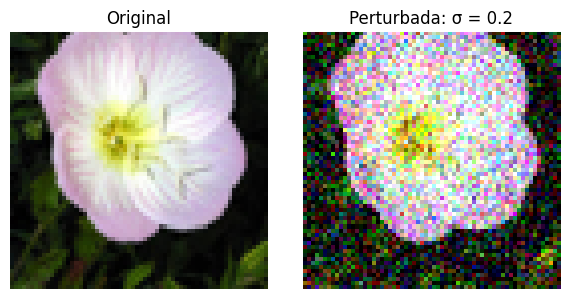

In [19]:
rng = np.random.default_rng(137)

# 1. Barajar y separar las imágenes.
indices = rng.permutation(len(imagenes))
corte = int(0.8 * len(imagenes))

entrenamiento = imagenes[indices[:corte]]
test = imagenes[indices[corte:]]

print("Entrenamiento:", entrenamiento.shape)
print("Test:", test.shape)

# 2. Perturbar todos los píxeles y canales.
sigma = 0.20  # Intensidad del ruido; las imágenes están entre 0 y 1.

def perturbar(X, sigma):
    ruido = rng.normal(size=X.shape).astype("float32")
    return X + sigma * ruido, ruido

entrenamiento_perturbado, ruido_train = perturbar(entrenamiento, sigma)
test_perturbado, ruido_test = perturbar(test, sigma)

# 3. Comparar una imagen antes y después.
i = 0

fig, ejes = plt.subplots(1, 2, figsize=(6, 3))

ejes[0].imshow(entrenamiento[i])
ejes[0].set_title("Original")

# Recortamos a [0, 1] únicamente para visualizar.
ejes[1].imshow(np.clip(entrenamiento_perturbado[i], 0, 1))
ejes[1].set_title(f"Perturbada: σ = {sigma}")

for eje in ejes:
    eje.axis("off")

plt.tight_layout()
plt.show()

In [20]:
keras.utils.set_random_seed(137)

modelo = keras.Sequential([
    keras.Input(shape=entrenamiento.shape[1:]),

    layers.Conv2D(
        32, kernel_size=3, padding="same", activation="relu"
    ),
    layers.Conv2D(
        32, kernel_size=3, padding="same", activation="relu"
    ),

    # Predecir el ruido de los tres canales RGB.
    layers.Conv2D(3, kernel_size=3, padding="same")
])

modelo.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="mse"
)

modelo.summary()

print("Entrada:", modelo.input_shape)
print("Salida:", modelo.output_shape)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 64, 64, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 64, 64, 3)      │           867 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,011 (43.01 KB)

 Trainable params: 11,011 (43.01 KB)

 Non-trainable params: 0 (0.00 B)

Entrada: (None, 64, 64, 3)
Salida: (None, 64, 64, 3)


In [21]:
sigma = 0.15
n_epocas = 20

perdidas_train = []
perdidas_test = []

# El test mantiene el mismo ruido durante toda la evaluación.
test_perturbado, ruido_test = perturbar(test, sigma)

for epoca in range(n_epocas):
    # Entrenamiento con ruido nuevo.
    entradas, ruido_real = perturbar(entrenamiento, sigma)

    historia = modelo.fit(
        entradas,
        ruido_real,
        epochs=1,
        batch_size=8,
        shuffle=True,
        verbose=0
    )

    mse_train = historia.history["loss"][0]

    # Evaluación: los pesos permanecen fijos.
    mse_test = modelo.evaluate(
        test_perturbado,
        ruido_test,
        batch_size=8,
        verbose=0
    )

    perdidas_train.append(mse_train)
    perdidas_test.append(mse_test)

    print(
        f"Época {epoca + 1:02d}/{n_epocas} | "
        f"Train: {mse_train:.4f} | Test: {mse_test:.4f}"
    )

# Graficar ambas curvas.
epocas = range(1, n_epocas + 1)

Época 01/20 | Train: 1.0013 | Test: 0.9849
Época 02/20 | Train: 0.9745 | Test: 0.9546
Época 03/20 | Train: 0.9381 | Test: 0.9105
Época 04/20 | Train: 0.8918 | Test: 0.8448
Época 05/20 | Train: 0.8144 | Test: 0.7685
Época 06/20 | Train: 0.7360 | Test: 0.6794
Época 07/20 | Train: 0.6462 | Test: 0.5927
Época 08/20 | Train: 0.5649 | Test: 0.5223
Época 09/20 | Train: 0.4983 | Test: 0.4600
Época 10/20 | Train: 0.4436 | Test: 0.4109
Época 11/20 | Train: 0.3969 | Test: 0.3702
Época 12/20 | Train: 0.3592 | Test: 0.3367
Época 13/20 | Train: 0.3302 | Test: 0.3095
Época 14/20 | Train: 0.3044 | Test: 0.2933
Época 15/20 | Train: 0.2841 | Test: 0.2728
Época 16/20 | Train: 0.2667 | Test: 0.2572
Época 17/20 | Train: 0.2516 | Test: 0.2462
Época 18/20 | Train: 0.2425 | Test: 0.2399
Época 19/20 | Train: 0.2313 | Test: 0.2296
Época 20/20 | Train: 0.2223 | Test: 0.2235


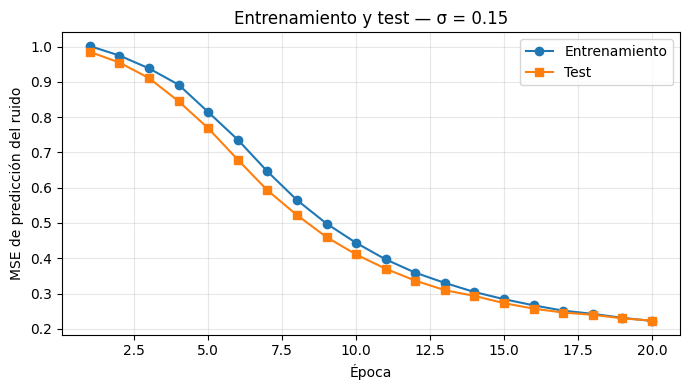

In [22]:
plt.figure(figsize=(7, 4))
plt.plot(epocas, perdidas_train, "o-", label="Entrenamiento")
plt.plot(epocas, perdidas_test, "s-", label="Test")
plt.xlabel("Época")
plt.ylabel("MSE de predicción del ruido")
plt.title(f"Entrenamiento y test — σ = {sigma}")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

MSE antes:   0.022521
MSE después: 0.005029


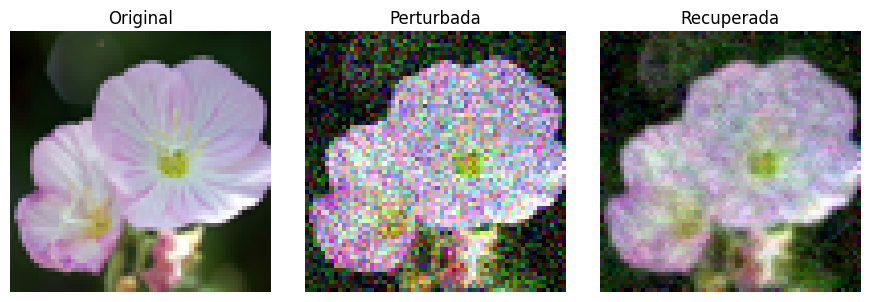

In [23]:
# Predecir el ruido y restarlo.
ruido_predicho = modelo.predict(
    test_perturbado, batch_size=8, verbose=0
)

sigma=0.15
recuperadas = test_perturbado - sigma * ruido_predicho

# Comparar el error respecto a las imágenes originales.
mse_antes = np.mean((test_perturbado - test)**2)
mse_despues = np.mean((recuperadas - test)**2)

print(f"MSE antes:   {mse_antes:.6f}")
print(f"MSE después: {mse_despues:.6f}")

# Visualizar una flor.
i = 3
fig, ejes = plt.subplots(1, 3, figsize=(9, 3))

comparacion = [
    (test[i], "Original"),
    (test_perturbado[i], "Perturbada"),
    (recuperadas[i], "Recuperada")
]

for eje, (imagen, titulo) in zip(ejes, comparacion):
    eje.imshow(np.clip(imagen, 0, 1))  # Recorte solo para mostrar.
    eje.set_title(titulo)
    eje.axis("off")

plt.tight_layout()
plt.show()

In [24]:
n_imagenes = 9
n_pasos = 5000
rng_generacion = np.random.default_rng(123)

# Paso pequeño de Langevin.
h = np.float32(0.005 * sigma**2)
amplitud = np.float32(np.sqrt(2 * h))

# Inicialización independiente de las flores originales.
forma = tuple(modelo.input_shape[1:])
generadas = rng_generacion.uniform(
    0, 1, size=(n_imagenes, *forma)
).astype("float32")

# Guardar la evolución de la primera imagen.
evolucion = {0: generadas[0].copy()}
guardar_en = {50, 100, 250, n_pasos}

# Inferencia con tu backend Torch: los pesos permanecen fijos.
with torch.no_grad():
    for paso in range(1, n_pasos + 1):

        # La red predice epsilon, no sigma * epsilon.
        ruido_predicho = keras.ops.convert_to_numpy(
            modelo(generadas, training=False)
        )

        score = -ruido_predicho / sigma

        # Ruido nuevo para la dinámica de Langevin.
        z = rng_generacion.normal(
            size=generadas.shape
        ).astype("float32")

        generadas = generadas + h * score + amplitud * z

        # Mantener los valores sin recortar durante la dinámica.
        if paso in guardar_en:
            evolucion[paso] = generadas[0].copy()

        if paso % 100 == 0:
            if not np.isfinite(generadas).all():
                raise FloatingPointError(
                    "La dinámica diverge. Reduce el valor de h."
                )
            print(f"\rPaso {paso}/{n_pasos}", end="", flush=True)


Paso 5000/5000

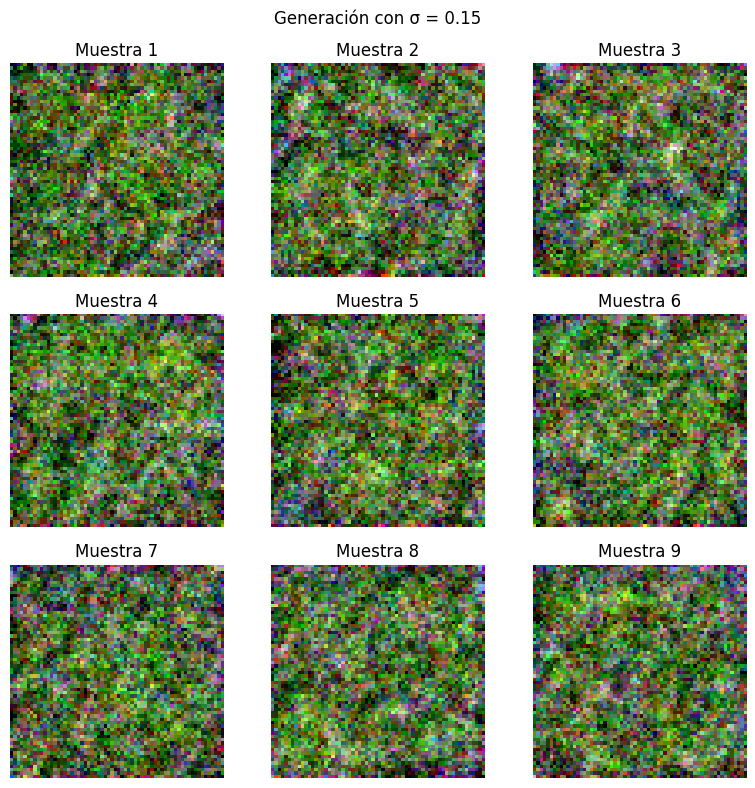

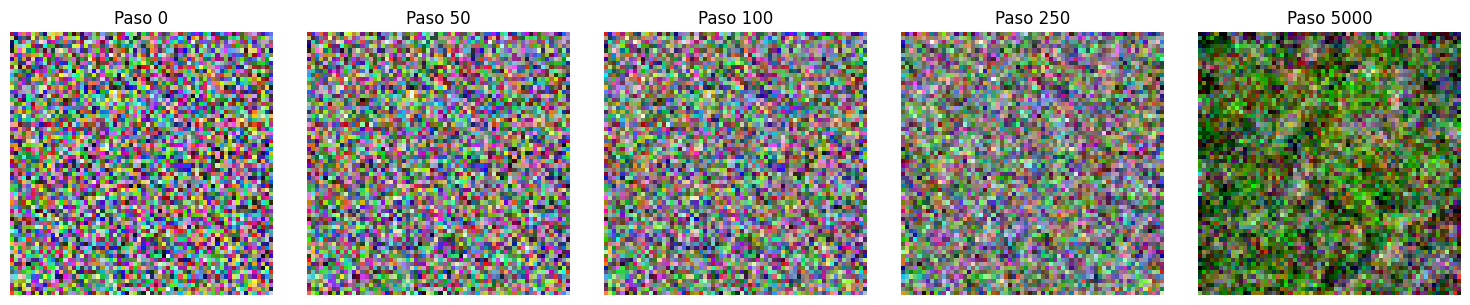

In [25]:
# Mostrar las nueve imágenes finales.
fig, ejes = plt.subplots(3, 3, figsize=(8, 8))

for i, eje in enumerate(ejes.flat):
    eje.imshow(np.clip(generadas[i], 0, 1))
    eje.set_title(f"Muestra {i + 1}")
    eje.axis("off")

fig.suptitle(f"Generación con σ = {float(sigma):.2f}")
plt.tight_layout()
plt.show()

# Mostrar cómo evolucionó la primera imagen.
fig, ejes = plt.subplots(
    1, len(evolucion), figsize=(3 * len(evolucion), 3)
)

for eje, (paso, imagen) in zip(ejes, evolucion.items()):
    eje.imshow(np.clip(imagen, 0, 1))
    eje.set_title(f"Paso {paso}")
    eje.axis("off")

plt.tight_layout()
plt.show()


Tarea laboratorio es : Implementar una red tipo Unet, para generar imagenes con una mejor aproximación

In [26]:
def build_unet(input_shape=(64, 64, 3)):
    inputs = keras.Input(shape=input_shape)

    # Encoder (Downsampling)
    conv1 = layers.Conv2D(32, 3, activation="relu", padding="same")(inputs)
    conv1 = layers.Conv2D(32, 3, activation="relu", padding="same")(conv1)
    pool1 = layers.MaxPooling2D(2)(conv1)

    conv2 = layers.Conv2D(64, 3, activation="relu", padding="same")(pool1)
    conv2 = layers.Conv2D(64, 3, activation="relu", padding="same")(conv2)
    pool2 = layers.MaxPooling2D(2)(conv2)

    # Bottleneck
    conv3 = layers.Conv2D(128, 3, activation="relu", padding="same")(pool2)
    conv3 = layers.Conv2D(128, 3, activation="relu", padding="same")(conv3)

    # Decoder (Upsampling)
    up4 = layers.UpSampling2D(2)(conv3)
    concat4 = layers.Concatenate()([up4, conv2])
    conv4 = layers.Conv2D(64, 3, activation="relu", padding="same")(concat4)
    conv4 = layers.Conv2D(64, 3, activation="relu", padding="same")(conv4)

    up5 = layers.UpSampling2D(2)(conv4)
    concat5 = layers.Concatenate()([up5, conv1])
    conv5 = layers.Conv2D(32, 3, activation="relu", padding="same")(concat5)
    conv5 = layers.Conv2D(32, 3, activation="relu", padding="same")(conv5)

    # Output layer to predict the 3 noise channels
    outputs = layers.Conv2D(3, 3, padding="same")(conv5)

    return keras.Model(inputs, outputs, name="UNet")

unet_modelo = build_unet(entrenamiento.shape[1:])
unet_modelo.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="mse"
)
unet_modelo.summary()

Model: "UNet"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 64, 64, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 64, 64,    │        896 │ input_layer_1[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 64, 64,    │      9,248 │ conv2d_3[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 32, 32,    │          0 │ conv2d_4[0][0]    │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 32, 32,    │     18,496 │ max_pooling2d[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_6 (Conv2D)   │ (None, 32, 32,    │     36,928 │ conv2d_5[0][0]    │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 16, 16,    │          0 │ conv2d_6[0][0]    │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_7 (Conv2D)   │ (None, 16, 16,    │     73,856 │ max_pooling2d_1[… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_8 (Conv2D)   │ (None, 16, 16,    │    147,584 │ conv2d_7[0][0]    │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_sampling2d       │ (None, 32, 32,    │          0 │ conv2d_8[0][0]    │
│ (UpSampling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 32, 32,    │          0 │ up_sampling2d[0]… │
│ (Concatenate)       │ 192)              │            │ conv2d_6[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_9 (Conv2D)   │ (None, 32, 32,    │    110,656 │ concatenate[0][0] │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_10 (Conv2D)  │ (None, 32, 32,    │     36,928 │ conv2d_9[0][0]    │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_sampling2d_1     │ (None, 64, 64,    │          0 │ conv2d_10[0][0]   │
│ (UpSampling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_1       │ (None, 64, 64,    │          0 │ up_sampling2d_1[… │
│ (Concatenate)       │ 96)               │            │ conv2d_4[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_11 (Conv2D)  │ (None, 64, 64,    │     27,680 │ concatenate_1[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_12 (Conv2D)  │ (None, 64, 64,    │      9,248 │ conv2d_11[0][0] 

 Total params: 472,387 (1.80 MB)

 Trainable params: 472,387 (1.80 MB)

 Non-trainable params: 0 (0.00 B)

In [27]:
# Entrenar el modelo UNet con ruido dinámico
sigma = 0.15
n_epocas = 25

perdidas_train_unet = []
perdidas_test_unet = []

test_perturbado, ruido_test = perturbar(test, sigma)

for epoca in range(n_epocas):
    entradas, ruido_real = perturbar(entrenamiento, sigma)
    historia = unet_modelo.fit(
        entradas,
        ruido_real,
        epochs=1,
        batch_size=8,
        shuffle=True,
        verbose=0
    )
    mse_train = historia.history["loss"][0]
    mse_test = unet_modelo.evaluate(
        test_perturbado,
        ruido_test,
        batch_size=8,
        verbose=0
    )
    perdidas_train_unet.append(mse_train)
    perdidas_test_unet.append(mse_test)

    if (epoca + 1) % 5 == 0 or epoca == 0:
        print(f"Época {epoca+1:02d}/{n_epocas} | Train MSE: {mse_train:.5f} | Test MSE: {mse_test:.5f}")

Época 01/25 | Train MSE: 0.98941 | Test MSE: 0.96929
Época 05/25 | Train MSE: 0.72384 | Test MSE: 0.66486
Época 10/25 | Train MSE: 0.39954 | Test MSE: 0.37853
Época 15/25 | Train MSE: 0.26491 | Test MSE: 0.25007
Época 20/25 | Train MSE: 0.20500 | Test MSE: 0.20032
Época 25/25 | Train MSE: 0.19452 | Test MSE: 0.18990


MSE con ruido inicial:     0.022577
MSE después de la U-Net:   0.004273


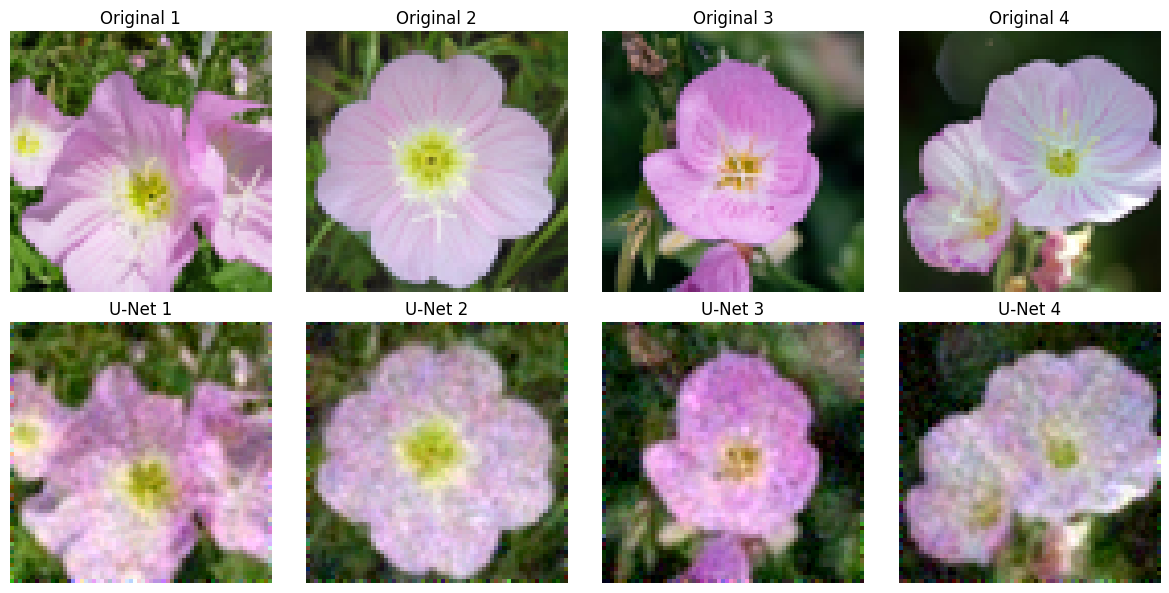

In [28]:
# Predecir el ruido usando el modelo U-Net entrenado
ruido_predicho_unet = unet_modelo.predict(
    test_perturbado, batch_size=8, verbose=0
)

# Reconstruir las imágenes
recuperadas_unet = test_perturbado - sigma * ruido_predicho_unet

# Calcular MSE final para evaluar la mejora
mse_inicial = np.mean((test_perturbado - test)**2)
mse_final_unet = np.mean((recuperadas_unet - test)**2)

print(f"MSE con ruido inicial:     {mse_inicial:.6f}")
print(f"MSE después de la U-Net:   {mse_final_unet:.6f}")

# Visualizar algunos resultados del conjunto de prueba
fig, ejes = plt.subplots(2, 4, figsize=(12, 6))

for col in range(4):
    # Imagen Original
    ejes[0, col].imshow(np.clip(test[col], 0, 1))
    ejes[0, col].set_title(f"Original {col+1}")
    ejes[0, col].axis("off")

    # Imagen reconstruida por U-Net
    ejes[1, col].imshow(np.clip(recuperadas_unet[col], 0, 1))
    ejes[1, col].set_title(f"U-Net {col+1}")
    ejes[1, col].axis("off")

plt.tight_layout()
plt.show()